# Digital Zero-Noise Extrapolation

Complete implementation for Bell State, Randomized, Variational and QAOA/MAXCUT circuits.

In [2]:
!pip -q install qiskit qiskit-aer scipy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 92.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.6 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

SHOTS = 5000
SCALES = [1, 3, 5]

noise_model = NoiseModel()
single_error = depolarizing_error(0.01, 1)
two_error = depolarizing_error(0.03, 2)
for gate in ["h", "x", "y", "z", "rx", "ry", "rz"]:
    noise_model.add_all_qubit_quantum_error(single_error, [gate])
noise_model.add_all_qubit_quantum_error(two_error, ["cx"])
print("Setup complete")

Setup complete


In [4]:
def measure_circuit(qc):
    measured = QuantumCircuit(qc.num_qubits, qc.num_qubits)
    measured.compose(qc, inplace=True)
    measured.measure(range(qc.num_qubits), range(qc.num_qubits))
    return measured

def parity_expectation(counts):
    total = sum(counts.values())
    value = 0
    for bitstring, count in counts.items():
        ones = bitstring.replace(" ", "").count("1")
        value += (1 if ones % 2 == 0 else -1) * count
    return value / total

def run_circuit(qc, noisy=False):
    simulator = AerSimulator(noise_model=noise_model if noisy else None)
    result = simulator.run(measure_circuit(qc), shots=SHOTS).result()
    return parity_expectation(result.get_counts())

def unitary_fold(qc, scale):
    folded = QuantumCircuit(qc.num_qubits)
    for _ in range((scale - 1) // 2):
        folded.compose(qc.inverse(), inplace=True)
        folded.compose(qc, inplace=True)
    folded.compose(qc, inplace=True)
    return folded

In [5]:
def linear_zne(x, y):
    return np.polyfit(x, y, 1)[1]

def polynomial_zne(x, y):
    return np.polyfit(x, y, 2)[2]

def richardson_zne(x, y):
    return (x[1] * y[0] - x[0] * y[1]) / (x[1] - x[0])

def exponential_zne(x, y):
    def model(x, a, b, c):
        return a + b * np.exp(-c * x)
    try:
        p, _ = curve_fit(model, x, y, p0=[y[-1], y[0] - y[-1], 0.1], maxfev=20000)
        return float(model(0, *p))
    except Exception:
        return linear_zne(x, y)

def run_experiment(name, qc):
    ideal = run_circuit(qc)
    noisy = run_circuit(qc, True)
    scaled = [run_circuit(unitary_fold(qc, s), True) for s in SCALES]
    return {
        "Circuit": name, "Ideal": ideal, "Noisy": noisy,
        "1x": scaled[0], "3x": scaled[1], "5x": scaled[2],
        "Linear ZNE": linear_zne(SCALES, scaled),
        "Polynomial ZNE": polynomial_zne(SCALES, scaled),
        "Richardson ZNE": richardson_zne(SCALES, scaled),
        "Exponential ZNE": exponential_zne(SCALES, scaled)
    }

## Bell State

In [6]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell_result = run_experiment("Bell State", bell)
bell_result

/tmp/ipykernel_948/3042248038.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(model, x, y, p0=[y[-1], y[0] - y[-1], 0.1], maxfev=20000)


{'Circuit': 'Bell State',
 'Ideal': 1.0,
 'Noisy': 0.9708,
 '1x': 0.9768,
 '3x': 0.8968,
 '5x': 0.8436,
 'Linear ZNE': np.float64(1.0056333333333327),
 'Polynomial ZNE': np.float64(1.0268499999999998),
 'Richardson ZNE': 1.0168,
 'Exponential ZNE': 1.030836699455506}

## Randomized Circuit

In [7]:
randomized = QuantumCircuit(3)
randomized.h(0)
randomized.ry(0.5, 1)
randomized.rx(0.7, 2)
randomized.cx(0, 1)
randomized.cx(1, 2)
randomized.rz(0.4, 0)
randomized_result = run_experiment("Randomized Circuit", randomized)
randomized_result

/tmp/ipykernel_948/3042248038.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(model, x, y, p0=[y[-1], y[0] - y[-1], 0.1], maxfev=20000)


{'Circuit': 'Randomized Circuit',
 'Ideal': 0.0012,
 'Noisy': 0.0004,
 '1x': -0.0124,
 '3x': -0.0204,
 '5x': -0.0004,
 'Linear ZNE': np.float64(-0.020066666666666653),
 'Polynomial ZNE': np.float64(0.0020999999999998706),
 'Richardson ZNE': -0.008399999999999998,
 'Exponential ZNE': -0.020066449792736307}

## Variational Circuit

In [8]:
variational = QuantumCircuit(2)
variational.ry(np.pi / 4, 0)
variational.ry(np.pi / 3, 1)
variational.cx(0, 1)
variational.ry(np.pi / 5, 0)
variational_result = run_experiment("Variational Circuit", variational)
variational_result

/tmp/ipykernel_948/3042248038.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(model, x, y, p0=[y[-1], y[0] - y[-1], 0.1], maxfev=20000)


{'Circuit': 'Variational Circuit',
 'Ideal': 0.4016,
 'Noisy': 0.3804,
 '1x': 0.398,
 '3x': 0.3652,
 '5x': 0.3244,
 'Linear ZNE': np.float64(0.4177333333333332),
 'Polynomial ZNE': np.float64(0.4113999999999997),
 'Richardson ZNE': 0.4144,
 'Exponential ZNE': 0.41773651821671365}

## QAOA/MAXCUT

In [9]:
qaoa = QuantumCircuit(3)
for q in range(3):
    qaoa.h(q)
for a, b in [(0, 1), (1, 2), (0, 2)]:
    qaoa.cx(a, b)
    qaoa.rz(0.8, b)
    qaoa.cx(a, b)
for q in range(3):
    qaoa.rx(0.6, q)
qaoa_result = run_experiment("QAOA/MAXCUT", qaoa)
qaoa_result

/tmp/ipykernel_948/3042248038.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  p, _ = curve_fit(model, x, y, p0=[y[-1], y[0] - y[-1], 0.1], maxfev=20000)


{'Circuit': 'QAOA/MAXCUT',
 'Ideal': 0.0132,
 'Noisy': -0.0312,
 '1x': 0.014,
 '3x': -0.0336,
 '5x': -0.0212,
 'Linear ZNE': np.float64(0.012799999999999997),
 'Polynomial ZNE': np.float64(0.060299999999999646),
 'Richardson ZNE': 0.0378,
 'Exponential ZNE': 86.64472964186174}

## Consolidated Results and Error Analysis

In [10]:
results = pd.DataFrame([bell_result, randomized_result, variational_result, qaoa_result])
methods = ["Noisy", "Linear ZNE", "Polynomial ZNE", "Richardson ZNE", "Exponential ZNE"]
for method in methods:
    results[method + " Abs Error"] = abs(results["Ideal"] - results[method])
for method in methods[1:]:
    results[method + " % Reduction"] = ((results["Noisy Abs Error"] - results[method + " Abs Error"]) / results["Noisy Abs Error"].replace(0, np.nan)) * 100
display(results.round(6))

,Circuit,Ideal,Noisy,1x,3x,5x,Linear ZNE,Polynomial ZNE,Richardson ZNE,Exponential ZNE,Noisy Abs Error,Linear ZNE Abs Error,Polynomial ZNE Abs Error,Richardson ZNE Abs Error,Exponential ZNE Abs Error,Linear ZNE % Reduction,Polynomial ZNE % Reduction,Richardson ZNE % Reduction,Exponential ZNE % Reduction
0,Bell State,1.0000,0.9708,0.9768,0.8968,0.8436,1.005633,1.02685,1.0168,1.030837,0.0292,0.005633,0.02685,0.0168,0.030837,80.707763,8.047945,42.465753,-5.605135
1,Randomized Circuit,0.0012,0.0004,-0.0124,-0.0204,-0.0004,-0.020067,0.00210,-0.0084,-0.020066,0.0008,0.021267,0.00090,0.0096,0.021266,-2558.333333,-12.500000,-1100.000000,-2558.306224
2,Variational Circuit,0.4016,0.3804,0.3980,0.3652,0.3244,0.417733,0.41140,0.4144,0.417737,0.0212,0.016133,0.00980,0.0128,0.016137,23.899371,53.773585,39.622642,23.884348
3,QAOA/MAXCUT,0.0132,-0.0312,0.0140,-0.0336,-0.0212,0.012800,0.06030,0.0378,86.644730,0.0444,0.000400,0.04710,0.0246,86.631530,99.099099,-6.081081,44.594595,-195016.057752


## Noise Scaling

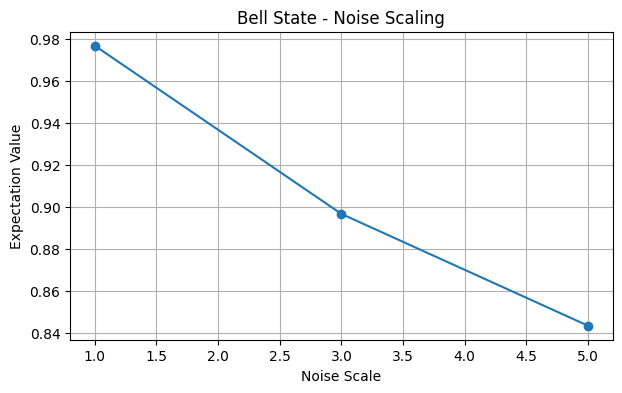

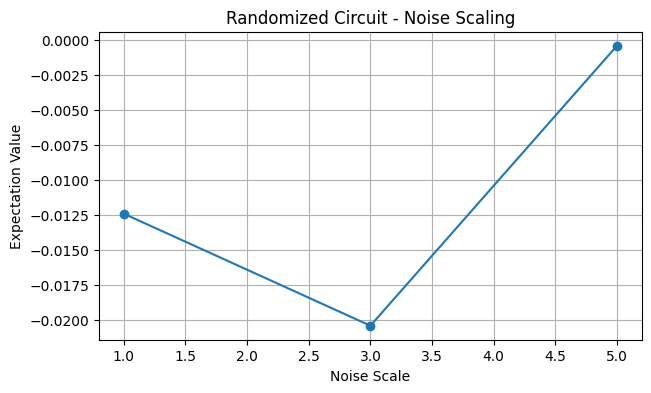

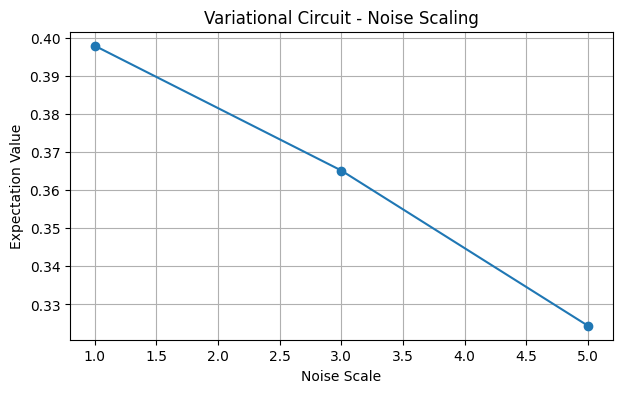

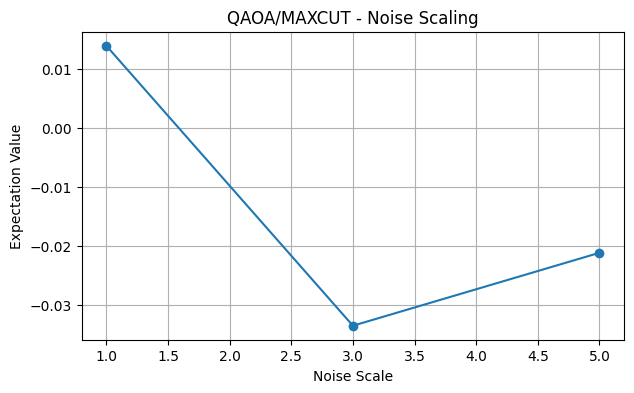

In [11]:
for row in [bell_result, randomized_result, variational_result, qaoa_result]:
    plt.figure(figsize=(7, 4))
    plt.plot(SCALES, [row["1x"], row["3x"], row["5x"]], marker="o")
    plt.xlabel("Noise Scale")
    plt.ylabel("Expectation Value")
    plt.title(row["Circuit"] + " - Noise Scaling")
    plt.grid(True)
    plt.show()

## ZNE Comparison

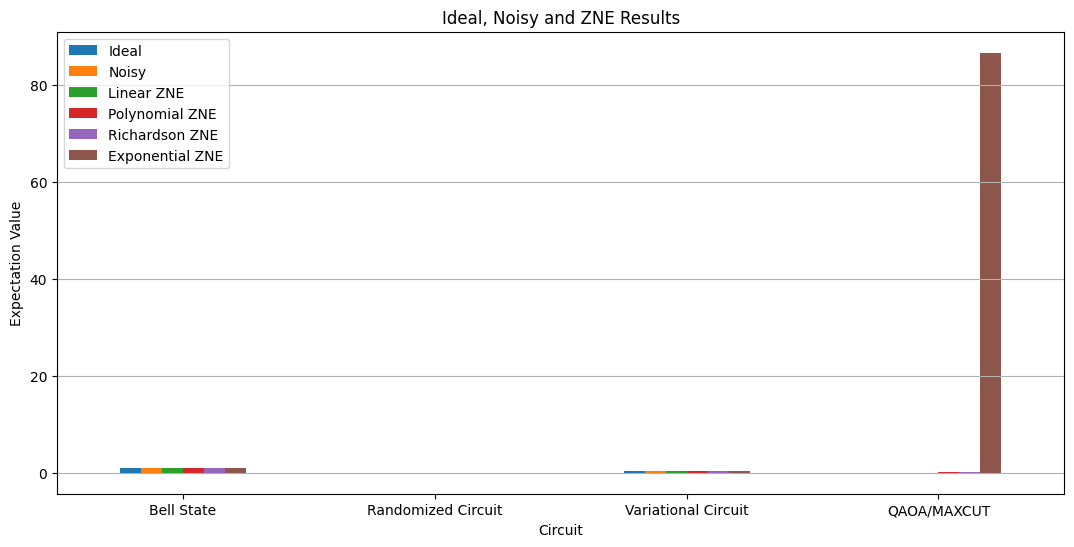

In [12]:
results.set_index("Circuit")[["Ideal", "Noisy", "Linear ZNE", "Polynomial ZNE", "Richardson ZNE", "Exponential ZNE"]].plot(kind="bar", figsize=(13, 6))
plt.ylabel("Expectation Value")
plt.title("Ideal, Noisy and ZNE Results")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

## Error Comparison

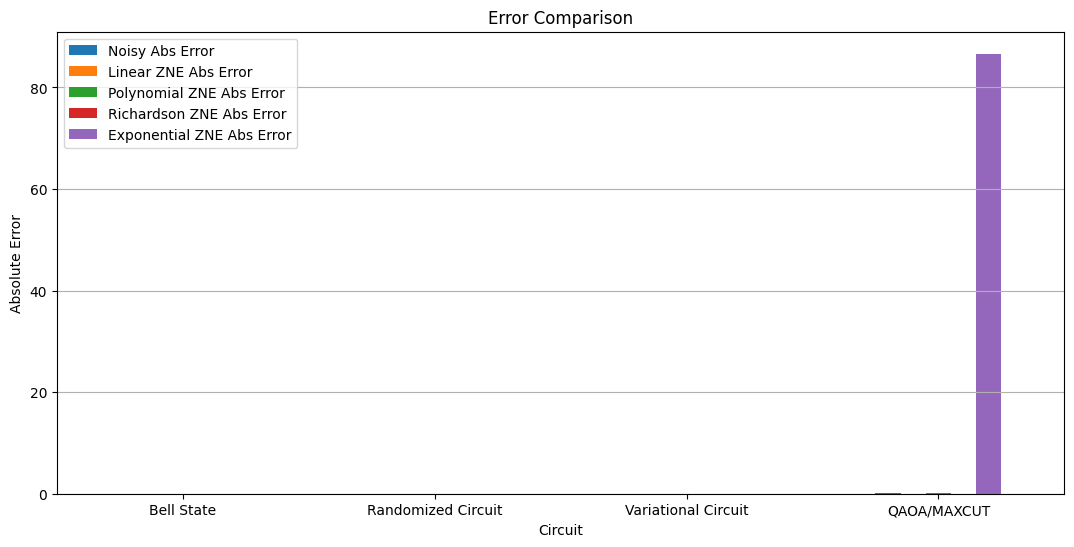

In [13]:
results.set_index("Circuit")[["Noisy Abs Error", "Linear ZNE Abs Error", "Polynomial ZNE Abs Error", "Richardson ZNE Abs Error", "Exponential ZNE Abs Error"]].plot(kind="bar", figsize=(13, 6))
plt.ylabel("Absolute Error")
plt.title("Error Comparison")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

## Error Reduction

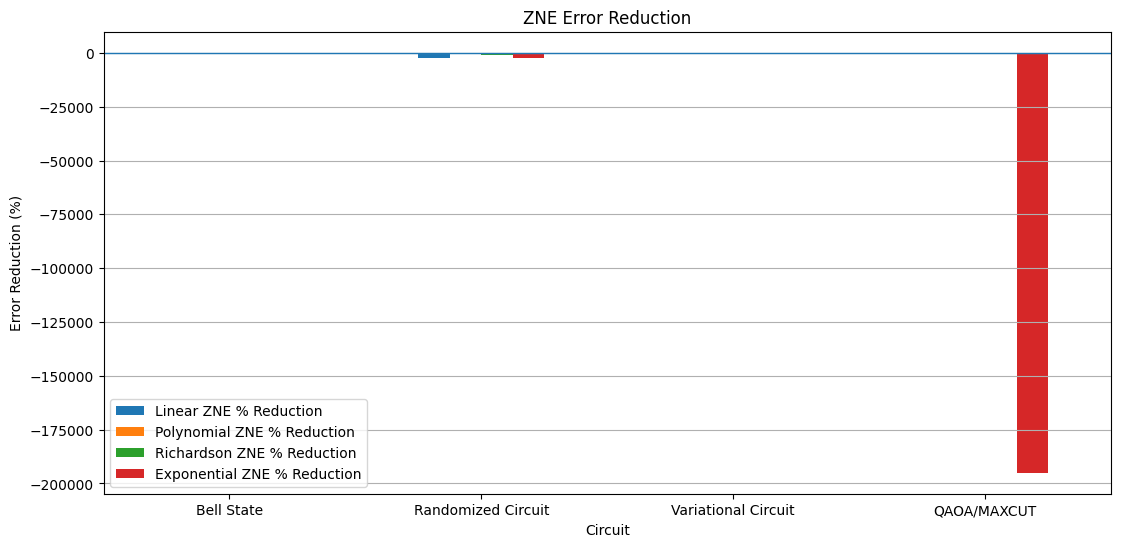

In [14]:
results.set_index("Circuit")[["Linear ZNE % Reduction", "Polynomial ZNE % Reduction", "Richardson ZNE % Reduction", "Exponential ZNE % Reduction"]].plot(kind="bar", figsize=(13, 6))
plt.ylabel("Error Reduction (%)")
plt.title("ZNE Error Reduction")
plt.xticks(rotation=0)
plt.axhline(0, linewidth=1)
plt.grid(axis="y")
plt.show()

## Resource Overhead

In [15]:
circuits = {"Bell State": bell, "Randomized Circuit": randomized, "Variational Circuit": variational, "QAOA/MAXCUT": qaoa}
rows = []
for name, qc in circuits.items():
    for scale in SCALES:
        folded = unitary_fold(qc, scale)
        rows.append({"Circuit": name, "Scale": scale, "Gate Count": len(folded.data), "Depth": folded.depth(), "Shots": SHOTS})
overhead = pd.DataFrame(rows)
display(overhead)

,Circuit,Scale,Gate Count,Depth,Shots
0,Bell State,1,2,2,5000
1,Bell State,3,6,6,5000
2,Bell State,5,10,10,5000
3,Randomized Circuit,1,6,3,5000
4,Randomized Circuit,3,18,9,5000
5,Randomized Circuit,5,30,15,5000
6,Variational Circuit,1,4,3,5000
7,Variational Circuit,3,12,9,5000
8,Variational Circuit,5,20,15,5000
9,QAOA/MAXCUT,1,15,11,5000


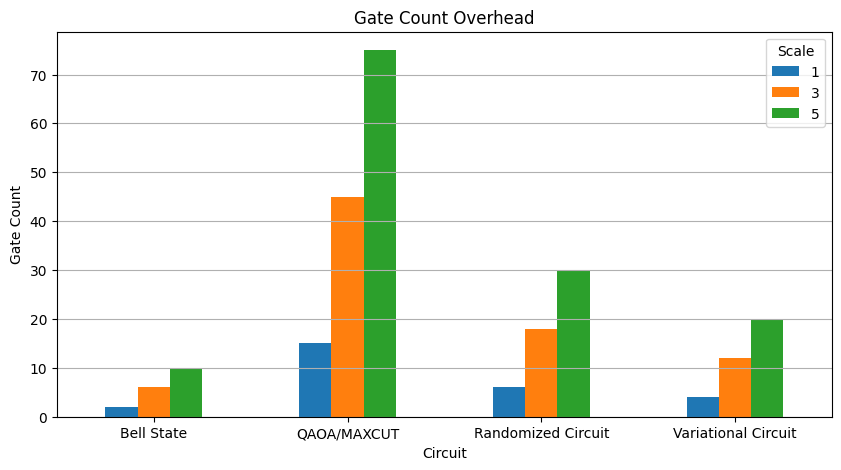

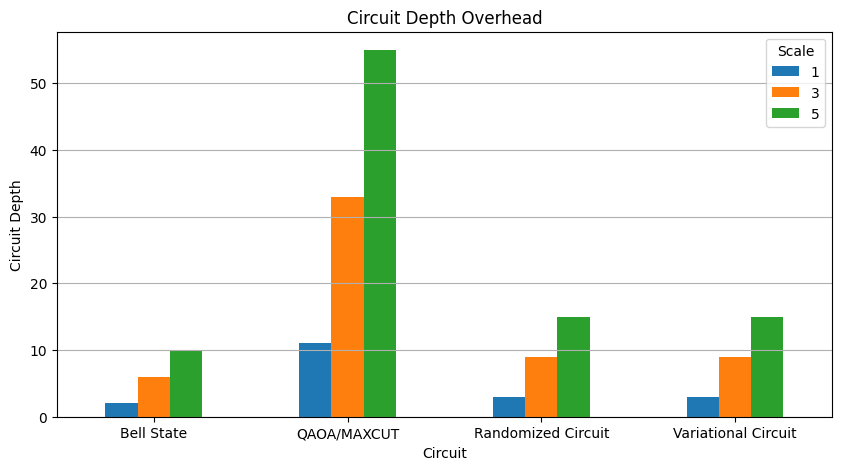

In [16]:
overhead.pivot(index="Circuit", columns="Scale", values="Gate Count").plot(kind="bar", figsize=(10, 5))
plt.ylabel("Gate Count")
plt.title("Gate Count Overhead")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

overhead.pivot(index="Circuit", columns="Scale", values="Depth").plot(kind="bar", figsize=(10, 5))
plt.ylabel("Circuit Depth")
plt.title("Circuit Depth Overhead")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

## Export Final Results

In [17]:
results.to_csv("ZNE_Final_Results.csv", index=False)
overhead.to_csv("ZNE_Resource_Overhead.csv", index=False)
print("ZNE_Final_Results.csv created")
print("ZNE_Resource_Overhead.csv created")

ZNE_Final_Results.csv created
ZNE_Resource_Overhead.csv created
